# Myopic policy dispatcher run

This notebook runs the checked-in myopic-policy dispatch config through `dasklite`, writes the Zarr result store under `artifacts/notebook_runs/`, and then reads the generated files back.

## Imports

In [1]:
import json
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import zarr
from dask.distributed import Client, LocalCluster

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import dasklite
from dasklite.dispatcher import dispatch_from_config

{
    "project_root": str(project_root),
    "dasklite_package": str(Path(dasklite.__file__).resolve()),
}


{'project_root': '/home/hdahmou/Network_creation',
 'dasklite_package': '/home/hdahmou/mini_projects/dasklite/dasklite/__init__.py'}

## Start a local Dask cluster

In [2]:
n_workers = 4
threads_per_worker = 1

cluster = LocalCluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    processes=False,
    dashboard_address=None,
)
client = Client(cluster)

{
    "scheduler_address": cluster.scheduler_address,
    "dashboard_link": client.dashboard_link,
    "n_workers": len(client.scheduler_info()["workers"]),
    "threads_per_worker": threads_per_worker,
}


{'scheduler_address': 'inproc://134.214.19.74/317788/1',
 'dashboard_link': 'http://134.214.19.74:8787/status',
 'n_workers': 4,
 'threads_per_worker': 1}

## Load the checked-in config and write a runtime copy

In [3]:
source_config_path = project_root / "configs" / "myopic_policy" / "baseline.dispatch_config.json"
source_config = json.loads(source_config_path.read_text(encoding="utf-8"))

started_slug = datetime.now().astimezone().strftime("%Y%m%dT%H%M%S")
run_dir = project_root / "artifacts" / "notebook_runs" / f"myopic-policy-{started_slug}"
run_dir.mkdir(parents=True, exist_ok=False)

runtime_config = dict(source_config)
runtime_config["scheduler_address"] = cluster.scheduler_address

runtime_config_path = run_dir / source_config_path.name
runtime_config_path.write_text(
    json.dumps(runtime_config, indent=2) + "\n",
    encoding="utf-8",
)

{
    "runtime_config_path": str(runtime_config_path),
    "scheduler_address": runtime_config["scheduler_address"],
    "write_batch_size": runtime_config["write_batch_size"],
}


{'runtime_config_path': '/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260331T203117/baseline.dispatch_config.json',
 'scheduler_address': 'inproc://134.214.19.74/317788/1',
 'write_batch_size': 4}

## Dispatch the task

In [4]:
dispatch_summary = dispatch_from_config(str(runtime_config_path))
dispatch_summary


{"ts": "2026-03-31T20:31:18", "level": "INFO", "logger": "dispatcher", "message": "Preparing task", "task_class": "tasks.myopic_policy:myopicPolicyRun"}
{"ts": "2026-03-31T20:31:19", "level": "INFO", "logger": "dispatcher", "message": "Task descriptions ready", "task_name": "myopic-policy", "task_count": 16}
{"ts": "2026-03-31T20:31:19", "level": "INFO", "logger": "dispatcher", "message": "Initialized output", "task_name": "myopic-policy", "output_zarr": "/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260331T203117/myopic-policy-20260331T203118.zarr", "batch_size": 4}
{"ts": "2026-03-31T20:31:19", "level": "INFO", "logger": "dispatcher", "message": "Connected to scheduler", "scheduler_address": "inproc://134.214.19.74/317788/1", "dashboard": "http://localhost:8787/status"}
{"ts": "2026-03-31T20:31:19", "level": "INFO", "logger": "dispatcher", "message": "Submitted tasks", "task_name": "myopic-policy", "task_count": 16}
{"ts": "2026-03-31T20:32:03", "level": "INF

{'success_count': 16,
 'failure_count': 0,
 'task_name': 'myopic-policy',
 'started_at': '20260331T203118',
 'task_class': 'tasks.myopic_policy:myopicPolicyRun',
 'success_rows_written': 16,
 'failure_rows_written': 0,
 'output_zarr': '/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260331T203117/myopic-policy-20260331T203118.zarr'}

## Read the generated Zarr store

In [9]:
result_store_path = Path(dispatch_summary["output_zarr"])
root = zarr.open_group(result_store_path, mode="r")
results_group = root["results"]
outputs_group = results_group["outputs"]

stored_outputs = {
    field["name"]: np.asarray(outputs_group[field["name"]])
    for field in root.attrs["output_schema"]
}

{
    "result_store_path": str(result_store_path),
    "task_name": root.attrs["task_name"],
    "task_class": root.attrs["task_class"],
    "output_schema": root.attrs["output_schema"],
    "total_inputs": root.attrs["total_inputs"],
    "stored_results": int(results_group["input_index"].shape[0]),
    "stored_failures": int(root["failures"]["input_index"].shape[0]),
    "run_dir_files": sorted(path.name for path in run_dir.iterdir()),
}


{'result_store_path': '/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260331T203117/myopic-policy-20260331T203118.zarr',
 'task_name': 'myopic-policy',
 'task_class': 'tasks.myopic_policy:myopicPolicyRun',
 'output_schema': [{'name': 'density.mean',
   'shape': [361],
   'dtype': 'float32'},
  {'name': 'social_welfare.mean', 'shape': [361], 'dtype': 'float32'}],
 'total_inputs': 16,
 'stored_results': 16,
 'stored_failures': 0,
 'run_dir_files': ['baseline.dispatch_config.json',
  'myopic-policy-20260331T203118.zarr']}

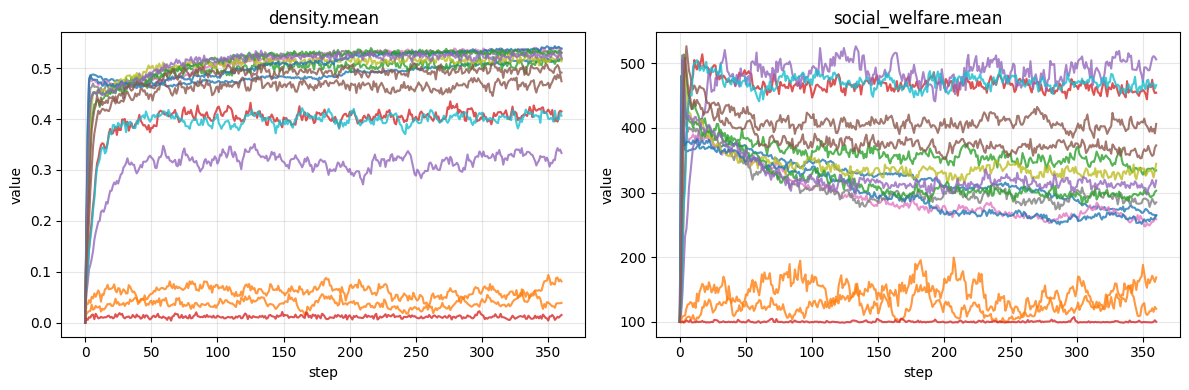

In [10]:
input_index = np.asarray(results_group["input_index"])
order = np.argsort(input_index)
steps = np.arange(stored_outputs["density.mean"].shape[1])

density_runs = stored_outputs["density.mean"][order]
welfare_runs = stored_outputs["social_welfare.mean"][order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for row_index, sample_idx in enumerate(input_index[order]):
    axes[0].plot(steps, density_runs[row_index], alpha=0.8, label=f"input {int(sample_idx)}")
    axes[1].plot(steps, welfare_runs[row_index], alpha=0.8, label=f"input {int(sample_idx)}")

axes[0].set_title("density.mean")
axes[0].set_xlabel("step")
axes[0].set_ylabel("value")
axes[0].grid(alpha=0.3)

axes[1].set_title("social_welfare.mean")
axes[1].set_xlabel("step")
axes[1].set_ylabel("value")
axes[1].grid(alpha=0.3)

if len(input_index) <= 10:
    axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()


In [11]:
{
    "input_index": input_index[order],
    "density.mean.final": density_runs[:, -1],
    "social_welfare.mean.final": welfare_runs[:, -1],
}


{'input_index': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15]),
 'density.mean.final': array([0.51777774, 0.03925926, 0.5170371 , 0.41481483, 0.33333334,
        0.4740741 , 0.537037  , 0.5303704 , 0.5133334 , 0.4066667 ,
        0.53851855, 0.08148148, 0.52962965, 0.01555556, 0.5207408 ,
        0.49111113], dtype=float32),
 'social_welfare.mean.final': array([264.83197, 120.24286, 334.28793, 454.55618, 506.10764, 406.32397,
        258.73468, 284.934  , 344.7627 , 466.42026, 264.85464, 168.751  ,
        302.94666, 100.16599, 318.67734, 373.12665], dtype=float32)}

## Cleanup

In [12]:
client.close()
cluster.close()
